# Step 4: Binary GreetingDetector - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Train binary classifier to detect greeting intents

**Date**: 2025-12-01

**Strategy**: Separate greeting from non-greeting intents

**Model**: Binary SVM with optimized TF-IDF features

## 1. Import Libraries

In [3]:
import numpy as np
import pandas as pd
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(42)

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load Features

In [4]:
print("=" * 80)
print("LOADING GREETING-OPTIMIZED FEATURES")
print("=" * 80)

# Load greeting TF-IDF features
X_greeting = np.load('../data/features/X_tfidf_greeting.npy')
y = np.load('../data/features/y.npy')

with open('../data/features/label_encoder.pickle', 'rb') as f:
    label_encoder = pickle.load(f)

print(f"X_greeting shape: {X_greeting.shape}")
print(f"y shape: {y.shape}")
print(f"Classes: {len(label_encoder.classes_)}")

LOADING GREETING-OPTIMIZED FEATURES
X_greeting shape: (2247, 500)
y shape: (2247,)
Classes: 88


## 3. Create Binary Labels

In [5]:
print("=" * 80)
print("CREATE BINARY LABELS")
print("=" * 80)

# Define greeting intents
greeting_intents = ['goodbye', 'greeting', 'pagi', 'siang', 'sore', 'malam']
greeting_indices = [i for i, cls in enumerate(label_encoder.classes_) if cls in greeting_intents]

print(f"Greeting intents: {greeting_intents}")
print(f"Greeting class indices: {greeting_indices}")

# Create binary labels: 1 = greeting, 0 = non-greeting
y_binary = np.array([1 if label in greeting_indices else 0 for label in y])

print(f"\nBinary label distribution:")
print(f"  Greeting (1): {(y_binary == 1).sum()} samples ({(y_binary == 1).sum() / len(y_binary) * 100:.1f}%)")
print(f"  Non-greeting (0): {(y_binary == 0).sum()} samples ({(y_binary == 0).sum() / len(y_binary) * 100:.1f}%)")

CREATE BINARY LABELS
Greeting intents: ['goodbye', 'greeting', 'pagi', 'siang', 'sore', 'malam']
Greeting class indices: [0, 1, 83, 84, 86, 87]

Binary label distribution:
  Greeting (1): 150 samples (6.7%)
  Non-greeting (0): 2097 samples (93.3%)


## 4. Train-Test Split

In [6]:
print("=" * 80)
print("TRAIN-TEST SPLIT")
print("=" * 80)

X_train, X_test, y_train, y_test = train_test_split(
    X_greeting, y_binary,
    test_size=0.2,
    random_state=42,
    stratify=y_binary
)

print(f"Train: {X_train.shape}")
print(f"Test: {X_test.shape}")
print(f"\nTrain distribution: Greeting={( y_train == 1).sum()}, Non-greeting={(y_train == 0).sum()}")
print(f"Test distribution: Greeting={(y_test == 1).sum()}, Non-greeting={(y_test == 0).sum()}")

TRAIN-TEST SPLIT
Train: (1797, 500)
Test: (450, 500)

Train distribution: Greeting=120, Non-greeting=1677
Test distribution: Greeting=30, Non-greeting=420


## 5. Train Binary SVM

In [7]:
print("=" * 80)
print("TRAINING BINARY GREETING DETECTOR")
print("=" * 80)

# Binary SVM with balanced class weights and probability
binary_svm = SVC(
    kernel='linear',
    C=1.0,
    class_weight='balanced',
    probability=True,
    random_state=42,
    verbose=True
)

print("\nTraining...")
binary_svm.fit(X_train, y_train)

print("\nTraining complete")
print(f"Support vectors: {binary_svm.n_support_}")

TRAINING BINARY GREETING DETECTOR

Training...
[LibSVM]
Training complete
Support vectors: [423  28]


## 6. Evaluate Performance

In [8]:
print("=" * 80)
print("EVALUATION")
print("=" * 80)

# Predictions
y_pred = binary_svm.predict(X_test)
y_proba = binary_svm.predict_proba(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nBinary Accuracy: {accuracy*100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(f"\nConfusion Matrix:")
print(cm)
print("[[TN FP]")
print(" [FN TP]]")

# Classification Report
print(f"\nClassification Report:")
report = classification_report(y_test, y_pred, target_names=['Non-Greeting', 'Greeting'], digits=4)
print(report)

# Analyze false positives and false negatives
fp_count = cm[0, 1]
fn_count = cm[1, 0]
print(f"\nError Analysis:")
print(f"  False Positives: {fp_count} (Non-greeting predicted as Greeting)")
print(f"  False Negatives: {fn_count} (Greeting predicted as Non-greeting)")

EVALUATION

Binary Accuracy: 100.00%

Confusion Matrix:
[[420   0]
 [  0  30]]
[[TN FP]
 [FN TP]]

Classification Report:
              precision    recall  f1-score   support

Non-Greeting     1.0000    1.0000    1.0000       420
    Greeting     1.0000    1.0000    1.0000        30

    accuracy                         1.0000       450
   macro avg     1.0000    1.0000    1.0000       450
weighted avg     1.0000    1.0000    1.0000       450


Error Analysis:
  False Positives: 0 (Non-greeting predicted as Greeting)
  False Negatives: 0 (Greeting predicted as Non-greeting)


## 7. Visualizations

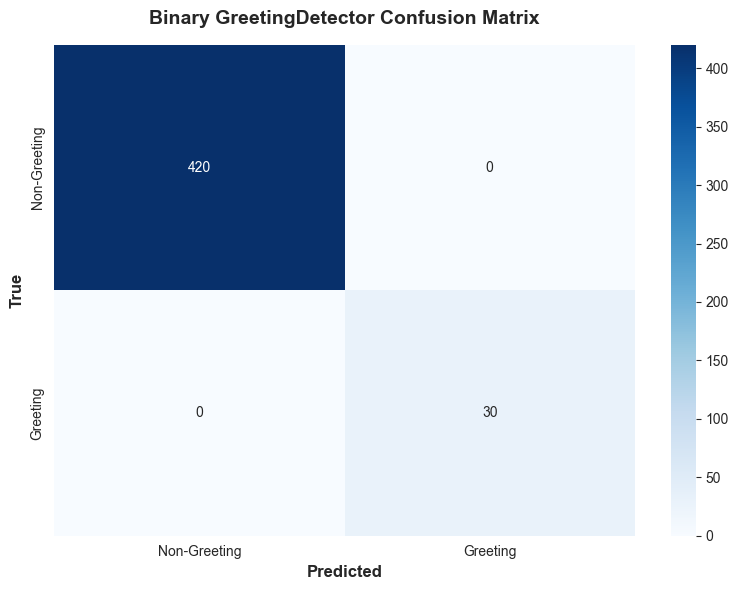

Confusion matrix saved


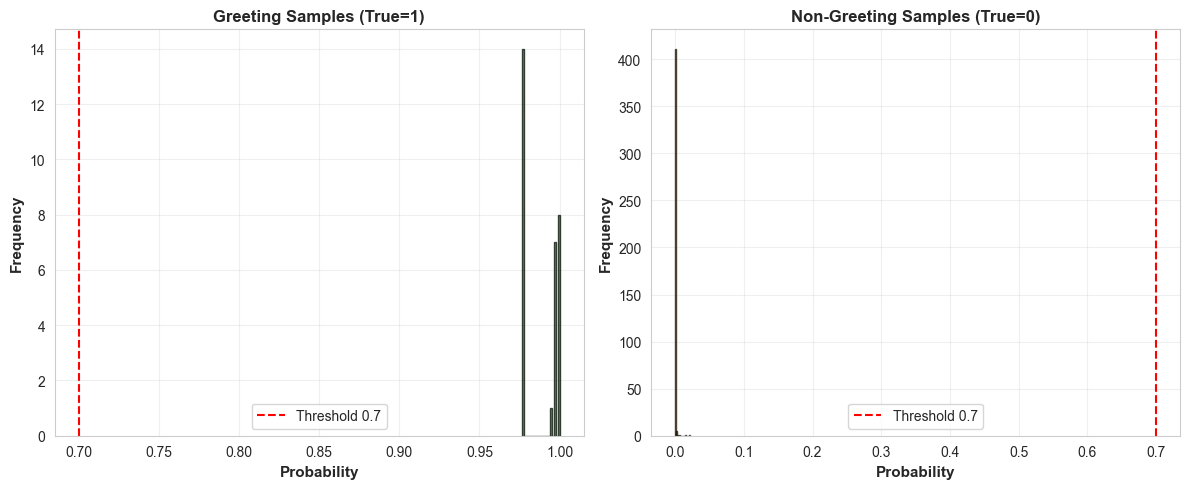

Probability distribution saved


In [9]:
# Confusion matrix heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-Greeting', 'Greeting'],
            yticklabels=['Non-Greeting', 'Greeting'])
plt.xlabel('Predicted', fontsize=12, fontweight='bold')
plt.ylabel('True', fontsize=12, fontweight='bold')
plt.title('Binary GreetingDetector Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
os.makedirs('../models', exist_ok=True)
plt.savefig('../models/greeting_detector_cm.png', dpi=300, bbox_inches='tight')
plt.show()

print("Confusion matrix saved")

# Probability distribution
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
greeting_proba = y_proba[y_test == 1, 1]
plt.hist(greeting_proba, bins=20, color='green', alpha=0.7, edgecolor='black')
plt.axvline(0.7, color='red', linestyle='--', label='Threshold 0.7')
plt.xlabel('Probability', fontsize=11, fontweight='bold')
plt.ylabel('Frequency', fontsize=11, fontweight='bold')
plt.title('Greeting Samples (True=1)', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
nongreeting_proba = y_proba[y_test == 0, 1]
plt.hist(nongreeting_proba, bins=20, color='orange', alpha=0.7, edgecolor='black')
plt.axvline(0.7, color='red', linestyle='--', label='Threshold 0.7')
plt.xlabel('Probability', fontsize=11, fontweight='bold')
plt.ylabel('Frequency', fontsize=11, fontweight='bold')
plt.title('Non-Greeting Samples (True=0)', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../models/greeting_detector_proba.png', dpi=300, bbox_inches='tight')
plt.show()

print("Probability distribution saved")

## 8. Save Model

In [10]:
print("=" * 80)
print("SAVING MODEL")
print("=" * 80)

# Save binary SVM
with open('../models/greeting_detector.pkl', 'wb') as f:
    pickle.dump(binary_svm, f)
print("Saved: greeting_detector.pkl")

# Save model info
from datetime import datetime
model_info = {
    'model_name': 'Binary_GreetingDetector',
    'algorithm': 'Binary SVM',
    'greeting_intents': greeting_intents,
    'accuracy': float(accuracy),
    'confusion_matrix': cm.tolist(),
    'train_samples': len(X_train),
    'test_samples': len(X_test),
    'greeting_samples': int((y_binary == 1).sum()),
    'non_greeting_samples': int((y_binary == 0).sum()),
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

with open('../models/greeting_detector_info.json', 'w') as f:
    json.dump(model_info, f, indent=2)
print("Saved: greeting_detector_info.json")

print("\nAll files saved successfully")

SAVING MODEL
Saved: greeting_detector.pkl
Saved: greeting_detector_info.json

All files saved successfully


## 9. Summary

In [11]:
print("=" * 80)
print("BINARY GREETING DETECTOR SUMMARY")
print("=" * 80)

print(f"\nModel: Binary SVM")
print(f"  Purpose: Detect greeting vs non-greeting intents")
print(f"  Greeting intents: {', '.join(greeting_intents)}")

print(f"\nData:")
print(f"  Total samples: {len(X_greeting)}")
print(f"  Greeting samples: {(y_binary == 1).sum()}")
print(f"  Non-greeting samples: {(y_binary == 0).sum()}")

print(f"\nPerformance:")
print(f"  Accuracy: {accuracy*100:.2f}%")
print(f"  False Positives: {cm[0, 1]}")
print(f"  False Negatives: {cm[1, 0]}")

print(f"\nUsage:")
print(f"  - Threshold 0.7 for confidence")
print(f"  - Probability >= 0.7 → GREETING")
print(f"  - Probability < 0.7 → NON-GREETING")

print("\n" + "=" * 80)

BINARY GREETING DETECTOR SUMMARY

Model: Binary SVM
  Purpose: Detect greeting vs non-greeting intents
  Greeting intents: goodbye, greeting, pagi, siang, sore, malam

Data:
  Total samples: 2247
  Greeting samples: 150
  Non-greeting samples: 2097

Performance:
  Accuracy: 100.00%
  False Positives: 0
  False Negatives: 0

Usage:
  - Threshold 0.7 for confidence
  - Probability >= 0.7 → GREETING
  - Probability < 0.7 → NON-GREETING

